# Mini Project 1 - Text Analysis

## Research Question

Are word-frequency patterns more similar between books written by the same author than between books written by different authors?

## Books

- *Pride and Prejudice* by Jane Austen
- *Emma* by Jane Austen
- *Jane Eyre* by Charlotte Brontë

## Goal

I want to see whether Jane Austen's two books have more similar word-frequency patterns than they have with Charlotte Brontë's *Jane Eyre*.

## Approach

I will download public-domain books from Project Gutenberg, clean the text, count word frequencies, normalize the frequencies because the books have different lengths, and compare the results.



## 1. Download and clean the books


In [1]:
import requests
import re
from collections import Counter
import math
import matplotlib.pyplot as plt

books = {
    "Pride and Prejudice": "https://www.gutenberg.org/cache/epub/1342/pg1342.txt",
    "Emma": "https://www.gutenberg.org/cache/epub/158/pg158.txt",
    "Jane Eyre": "https://www.gutenberg.org/cache/epub/1260/pg1260.txt"
}

def download_book(url):
    r = requests.get(
        url,
        timeout=30,
        headers={"User-Agent": "UTK COSC445 student project"}
    )
    r.raise_for_status()
    return r.text

def remove_gutenberg_text(text):
    start = re.search(
        r"\*\*\*\s*START OF (?:THE )?PROJECT GUTENBERG EBOOK.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    if start:
        text = text[start.end():]

    end = re.search(
        r"\*\*\*\s*END OF (?:THE )?PROJECT GUTENBERG EBOOK.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    if end:
        text = text[:end.start()]

    return text

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

tokens = {}

for title, url in books.items():
    raw = download_book(url)
    cleaned = remove_gutenberg_text(raw)
    tokens[title] = tokenize(cleaned)

    print(title, "-", f"{len(tokens[title]):,}", "words")



Pride and Prejudice - 128,565 words


Emma - 162,099 words


Jane Eyre - 189,604 words


## 2. Remove common stop words

I remove very common English words for the main content-word comparison. I also normalize frequencies per 10,000 words because the books have different lengths.



In [2]:
stop_words = set("""
a an the and or but if while with without to of in on at by for from into
is am are was were be been being have has had having do does did doing
this that these those it its he him his she her hers they them their theirs
we us our ours you your yours i me my mine who whom whose which what
as than then so because although though since until when where why how
not no nor too very can could may might must shall should will would
all any both each few more most other some such only own same
up down out over under again further once here there
""".split())

def content_words(words):
    return [
        word for word in words
        if word not in stop_words and len(word) > 1
    ]

def normalized_frequencies(words):
    counts = Counter(words)
    total = len(words)

    return {
        word: count / total * 10000
        for word, count in counts.items()
    }

content = {}
frequencies = {}

for title in books:
    content[title] = content_words(tokens[title])
    frequencies[title] = normalized_frequencies(content[title])

    print(title, "-", f"{len(content[title]):,}", "content words")



Pride and Prejudice - 57,214 content words
Emma - 71,842 content words
Jane Eyre - 88,613 content words


## 3. Most common content words


In [3]:
def top_words(title, n=15):
    return sorted(
        frequencies[title].items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

for title in books:
    print("\n" + title)
    print("-" * len(title))

    for word, rate in top_words(title):
        print(f"{word:18s} {rate:8.2f}")




Pride and Prejudice
-------------------
mr                   141.22
elizabeth            112.73
darcy                 75.51
said                  70.96
mrs                   61.87
bennet                59.25
much                  58.90
miss                  55.06
bingley               54.18
jane                  52.78
one                   51.56
know                  42.65
herself               41.25
well                  40.20
never                 40.20

Emma
----
mr                   160.63
emma                 120.40
mrs                   97.58
miss                  83.79
harriet               70.43
much                  67.65
said                  67.37
one                   63.75
weston                61.25
every                 60.55
well                  56.10
thing                 55.54
knightley             54.15
elton                 53.87
think                 53.45

Jane Eyre
---------
now                   75.27
one                   67.15
said                  65.90
mr 

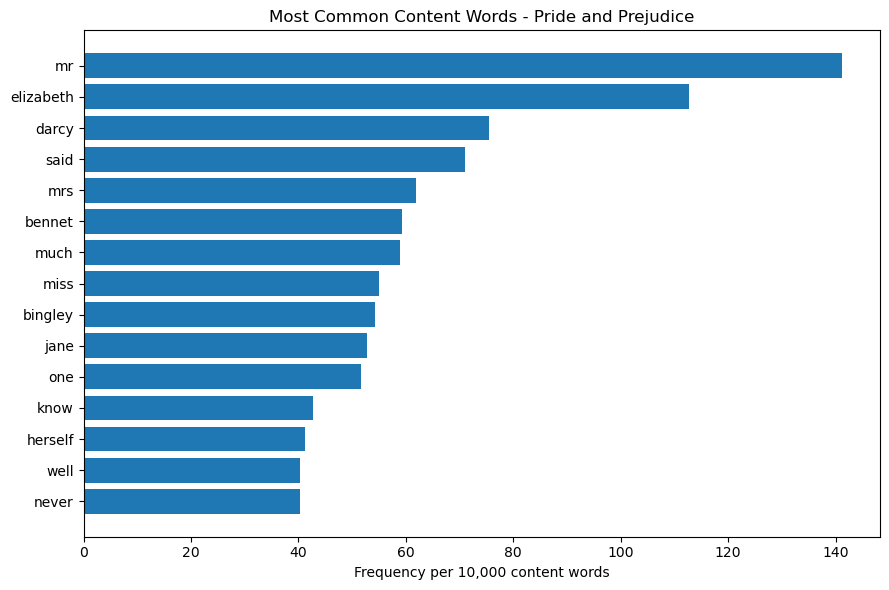

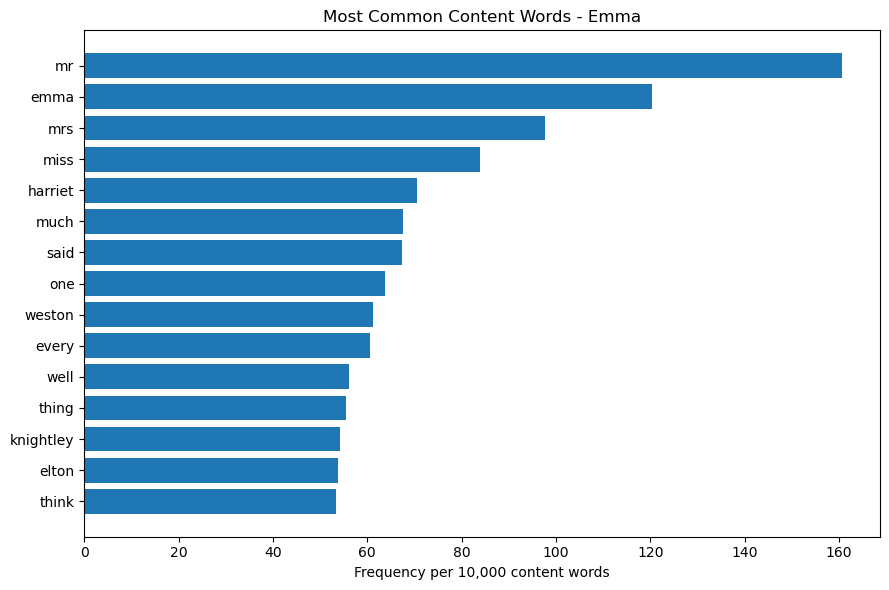

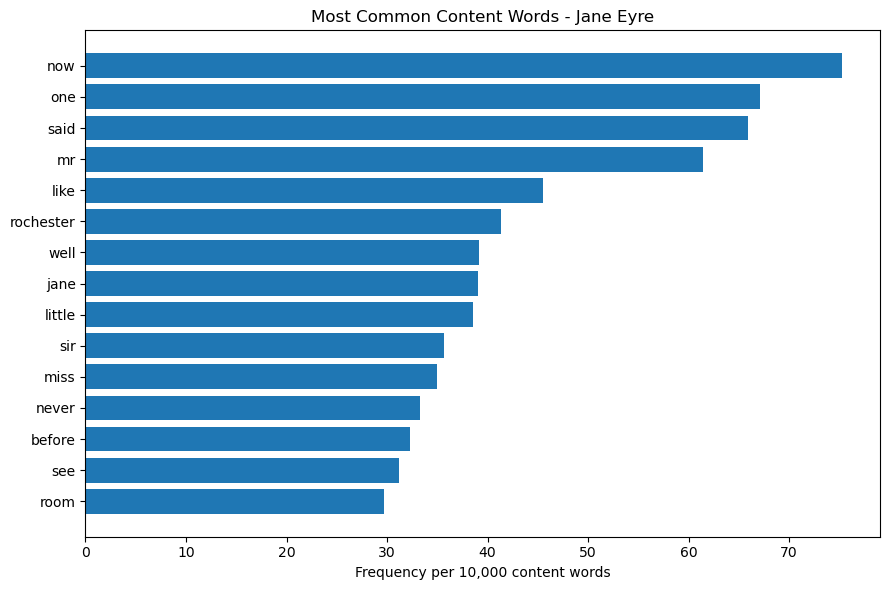

In [4]:
def plot_top_words(title):
    data = top_words(title)[::-1]

    words = [x[0] for x in data]
    rates = [x[1] for x in data]

    plt.figure(figsize=(9, 6))
    plt.barh(words, rates)
    plt.xlabel("Frequency per 10,000 content words")
    plt.title("Most Common Content Words - " + title)
    plt.tight_layout()
    plt.show()

for title in books:
    plot_top_words(title)



## 4. Compare overall word-frequency similarity

I use cosine similarity. A score closer to 1 means the frequency patterns are more similar.



In [5]:
def cosine_similarity(title1, title2):
    f1 = frequencies[title1]
    f2 = frequencies[title2]

    vocab = set(f1) | set(f2)

    dot = sum(
        f1.get(w, 0) * f2.get(w, 0)
        for w in vocab
    )

    mag1 = math.sqrt(sum(f1.get(w, 0) ** 2 for w in vocab))
    mag2 = math.sqrt(sum(f2.get(w, 0) ** 2 for w in vocab))

    return dot / (mag1 * mag2)

same_author = cosine_similarity(
    "Pride and Prejudice",
    "Emma"
)

different_1 = cosine_similarity(
    "Pride and Prejudice",
    "Jane Eyre"
)

different_2 = cosine_similarity(
    "Emma",
    "Jane Eyre"
)

print("Cosine similarity")
print("-----------------")
print("Pride and Prejudice vs Emma:", round(same_author, 4))
print("Pride and Prejudice vs Jane Eyre:", round(different_1, 4))
print("Emma vs Jane Eyre:", round(different_2, 4))



Cosine similarity
-----------------
Pride and Prejudice vs Emma: 0.7477
Pride and Prejudice vs Jane Eyre: 0.7041
Emma vs Jane Eyre: 0.7093


## 5. Selected style words


In [6]:
style_words = [
    "would", "could", "should", "might",
    "must", "shall", "perhaps", "rather",
    "never", "always", "quite", "much"
]

def rate(title, word):
    counts = Counter(tokens[title])
    return counts[word] / len(tokens[title]) * 10000

print(f"{'Word':12s} {'P&P':>10s} {'Emma':>10s} {'Jane Eyre':>10s}")

for word in style_words:
    print(
        f"{word:12s}"
        f"{rate('Pride and Prejudice', word):10.2f}"
        f"{rate('Emma', word):10.2f}"
        f"{rate('Jane Eyre', word):10.2f}"
    )



Word                P&P       Emma  Jane Eyre
would            37.72     50.65     35.07
could            41.30     51.64     26.63
should           20.07     22.89     15.19
might            16.02     20.11      8.54
must             24.50     35.23     16.35
shall            12.68     13.51     12.71
perhaps           6.92      6.11      5.49
rather            4.82      9.01      6.54
never            17.89     22.09     15.56


always            9.80     14.68      4.59
quite             7.62     17.40      7.49
much             26.21     29.98     10.97


## Problems / Limitations

1. The books have different lengths, so I normalized the frequencies.
2. Character names and story topics can strongly affect word counts.
3. *Jane Eyre* uses first-person narration, while the Austen novels use a different narrative style.
4. Word frequency alone cannot prove authorship.
5. Cleaning and stop-word choices can affect the results.



## Results

The two Jane Austen books had the highest word-frequency similarity. *Pride and Prejudice* and *Emma* had a cosine similarity of **0.7477**. In comparison, *Pride and Prejudice* and *Jane Eyre* had a similarity of **0.7041**, while *Emma* and *Jane Eyre* had a similarity of **0.7093**.

This supports my original idea that books written by the same author may have more similar word-frequency patterns. However, the difference was not extremely large. Things such as story topic, characters, and narration style can also affect word use, so these results do not prove authorship by themselves.

## Conclusion

Based on these three books, Jane Austen's two novels were more similar to each other than either one was to Charlotte Brontë's *Jane Eyre*. This suggests that word frequency can capture some differences in writing patterns. At the same time, I would need to compare more books and more writing features before making a stronger conclusion.



## New Ideas

A future analysis could compare more books from each author, sentence length, punctuation, word length, or function-word patterns.

